# Will this station be congested in the next 30 minutes? Which features does the model need?

The target is the team's yes/no question for the early-warning map (defined in `safeflow_features.py`):

> **Will this station be congested at any point in the next 30 minutes?**

- **Congested** means a measured speed below `SLOW_MPH` (40 mph). Rows count only if all six future readings were measured.
- **The model** is the team's boosted trees (`HistGradientBoostingClassifier` with the settings of `feature_selection.ipynb`).
- **The candidates** are the 29 shared features in `sf.SHARED_FEATURES` (the original 16 plus the 13 added on 31 Oct) and 4 new ones
  built in this notebook.
- **Features are chosen on the first three validation quarters** (2024 Q1–Q3) and confirmed on all six. The last three quarters
  (2024 Q4–2025 Q2) play no part in choosing, so they are the fair test.

`safeflow_features.py` is used as it is; nothing in it or anywhere else in the repo changes. **The July–December 2025 holdout is never read.**

**Contents**
1. Load the data
2. Features
3. The target
4. How correlated are the features?
5. Do three different methods agree a feature matters? (check a)
6. Does a feature beat random noise? (check b)
7. Which features earn their place? (check c: drop and refit)
8. The selected set
9. Walk-forward validation (six quarterly folds)
10. Catching jams vs. false alarms, at every threshold
11. Calibration
12. What the model relies on
13. Notes

**How a feature is chosen**

| Check | Question | Passes if |
|---|---|---|
| **(a) Vote** | Do three different methods (mutual information, L1 logistic regression, random forest) rank it highly? | at least 2 of the 3 name it in their top `TOP_N`, in at least `MIN_QUARTERS` of the 3 quarters |
| **(b) Shadow features** | Is it more useful than random noise? Every feature gets a shuffled copy, which carries no signal | its mean \|SHAP\| beats every shuffled copy, in at least `MIN_QUARTERS` quarters |
| **(c) Drop and refit** | Does the model lose AP without it? Tested inside families of correlated features, which share credit | dropping it lowers AP in at least `MIN_QUARTERS` quarters (a family always keeps its strongest member) |

**Selected** = features that pass (a) or (b), then survive (c).

**How it's judged**

| Measure | Meaning | Better |
|---|---|---|
| **AP, onsets** | Average precision on rows where the station is *not* congested now. This is the hard, useful case: will a jam *start*? | higher |
| **AP, all** | Average precision on every scored row | higher |
| **Brier score** | Average squared gap between the probability and what happened (0 = perfect) | lower |
| **Caught ≥15 min** | Of the congestion onsets, the share flagged at least 15 minutes ahead (probability ≥ `ALERT_THRESHOLD`) | higher |
| **False alarms / day** | Alert episodes per validation day where no congestion followed within 30 minutes | lower |
| **Wrong-alert hours / day** | Total time, summed over stations, that an alert was on and no congestion followed | lower |

Two simple guesses are included for reference, as in `feature_selection.ipynb`: **same as now** (congested now → predict congested) and
**typical for this time** (how often this station was congested within 30 minutes at this time of day in the training data).

In [1]:
# Resolve repository paths from the root or any notebook subfolder.
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks" / "safeflow_features.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from inside the SafeFlow repository")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))

# ---- Settings ---------------------------------------------------------------------------------------
DATA_DIR = None                                        # None = find a folder named "Data" here or in a parent folder

# Choosing features: checks (a)-(c) run on the first SELECTION_QUARTERS validation quarters
SELECTION_QUARTERS = 3                                 # 2024 Q1-Q3 choose; the last three quarters only confirm
MIN_QUARTERS = 2                                       # "consistently" = in at least this many of the selection quarters
TOP_N = 15                                             # check (a): each method names its top 15
FIT_SAMPLE = 300_000                                   # checks (a)-(c): training rows per quarter (random sample)
VOTE_SAMPLE = 30_000                                   # check (a): rows for mutual information and L1 logistic regression
SHAP_ROWS = 30_000                                     # check (b) and section 12: validation rows explained
FAMILY_CORR = 0.8                                      # check (c): candidates all correlated above this form a family
CHECK_PARAMS = dict(max_iter=150, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=50,
                    early_stopping=False, random_state=0)          # a faster version of the team's model, for check (c)

# Confirming: the team's boosted trees and sampling (as in feature_selection.ipynb and train_and_evaluate.ipynb)
TREE_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                   early_stopping=False, random_state=0)
TRAIN_SAMPLE = 2_000_000                               # max training rows per fit (None = use all, slower)

In [2]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import average_precision_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

import safeflow_features as sf

try:
    from lightgbm import LGBMClassifier                # pip install lightgbm (needed for check (b) and the SHAP plots)
except ImportError:
    LGBMClassifier = None
    print("lightgbm not installed: check (b) and the SHAP plots are skipped")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)

# Chart style (as in feature_selection.ipynb)
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRAY, DARK_GRAY = "#b5b4ae", "#8f8e88"
INK, INK2, GRID, BACKGROUND = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110,
})
ORIGIN_COLORS = {"original 16": BLUE, "added 31 Oct": ORANGE, "new": AQUA}     # where each feature comes from

## 1. Load the data
The team's dataset from `sf.build_dataset()`: weekdays without federal holidays, 6:00–19:55, January 2023 to June 2025. Holdout files are skipped
before they are opened.

In [3]:
df = sf.build_dataset(DATA_DIR)

SHARED_NOW = list(sf.SHARED_FEATURES)                                     # the 29 every model uses now
ADDED_31_OCT = list(getattr(sf, "TRANSFORMER_ADDITIONAL_FEATURES", []))   # the 13 added with the transformer
SHARED_16 = [f for f in SHARED_NOW if f not in ADDED_31_OCT]              # the original 16 (decorrelated + downstream)
print(f"{len(SHARED_NOW)} shared features: {len(SHARED_16)} original + {len(ADDED_31_OCT)} added on 31 Oct")

read 100/1094 files (2s)


read 200/1094 files (4s)


read 300/1094 files (6s)


read 500/1094 files (10s)


read 600/1094 files (12s)


read 800/1094 files (15s)


read 900/1094 files (17s)


624 weekdays used out of 1094 files (182 holdout files skipped, never read)


4,819,328 rows | 46 stations | scored rows 54% | onsets 13,573
29 shared features: 16 original + 13 added on 31 Oct


## 2. Features
Every feature is computed at the forecast time from information available then.

**The 29 shared features** (`sf.SHARED_FEATURES`)

| Group | Features | Added |
|---|---|---|
| speed and occupancy now | `speed_anomaly`, `occ_anomaly`, `flow` | original 16 |
| | `speed`, `occupancy` | 31 Oct |
| recent speed changes | `speed_delta_2` | original 16 |
| | `speed_delta_1`, `speed_delta_3` | 31 Oct |
| recent history | `slow_last_30` (slow readings in the last 30 min), `minutes_since_slow`, `speed_lag_30` | 31 Oct |
| typical conditions | `typical_congestion_30` (share of training days congested within 30 min, this station and time) | original 16 |
| nearest neighbors | `down_minus_here`, `up_minus_here` | original 16 |
| | `upstream_speed_delta_1/2/3`, `downstream_speed_delta_1/2`, `upstream_distance_miles` | 31 Oct |
| downstream jam | `jam_distance_down`, `min_speed_down_anomaly`, `jam_distance_change_10` | original 16 |
| ramps | `onramp_flow_up`, `offramp_flow_down` | original 16 |
| time and place | `tod_sin`, `tod_cos`, `dow`, `pm` | original 16 |

**4 new candidates**, built here from past and current readings only

| Feature | Meaning | Why it might help |
|---|---|---|
| `downstream_occ` | occupancy at the next station downstream, now (already built by `build_dataset()`, not in the shared list) | density building just ahead comes before the slowdown reaches this station |
| `outflow_down` | flow here − flow at the next station downstream, now | more cars arriving than leaving the next stretch = a queue forming |
| `speed_min_30` | lowest speed at this station in the last 30 minutes (now and the 5 readings before) | a station that dipped close to 40 recently is close to "yes" |
| `typical_in_30` | this station's typical speed 30 minutes from now (rebuilt per fold by `sf.add_typical_features`, own day left out) | where the usual daily pattern is heading |

In [4]:
stations = sf._LAST_CONTEXT.stations                   # station order (upstream / downstream neighbors) from build_dataset()


def downstream_flow(d):
    # Flow at the next station downstream, at the same 5-minute timestamp.
    neighbor_of = stations[["ID", "downstream_id"]].rename(columns={"ID": "station", "downstream_id": "neighbor"})
    flows = d[sf.KEY + ["flow"]].rename(columns={"station": "neighbor", "flow": "downstream_flow"})
    matched = d[sf.KEY].merge(neighbor_of, on="station", how="left").merge(flows, on=["neighbor", "timestamp"], how="left")
    return matched["downstream_flow"].to_numpy()


def outflow_down(d):
    # Flow here minus flow at the next station downstream (positive = more cars arriving than leaving).
    return (d["flow"].to_numpy() - downstream_flow(d)).astype("float32")


def speed_min_30(d):
    # Lowest speed at this station now and in the 5 readings before (the last 30 minutes).
    readings = [d["speed"].to_numpy()] + [sf.same_station_at(d, "speed", -m) for m in range(5, 30, 5)]
    return np.fmin.reduce(np.vstack(readings).astype(float), axis=0).astype("float32")


df["outflow_down"] = outflow_down(df)
df["speed_min_30"] = speed_min_30(df)

NEW_FEATURES = ["downstream_occ", "outflow_down", "speed_min_30", "typical_in_30"]
CANDIDATES = SHARED_NOW + [f for f in NEW_FEATURES if f not in SHARED_NOW]
ORIGIN = {f: "original 16" if f in SHARED_16 else "added 31 Oct" if f in ADDED_31_OCT else "new" for f in CANDIDATES}
print(f"{len(CANDIDATES)} candidates: " + ", ".join(f"{n} {o}" for o, n in pd.Series(ORIGIN).value_counts().items()))

33 candidates: 16 original 16, 13 added 31 Oct, 4 new


**Look-ahead check.** For three days, every reading after 16:00 is removed, the features are recomputed from what's left, and compared with
their values in the full data up to 16:00. A feature that changes uses readings from after the forecast time. Checked: the two new features
built here and the 13 added on 31 Oct, which `sf.check_no_lookahead()` doesn't cover (they aren't registered with `@feature`). Rows from 8:05
on are compared, so the 2-hour look-back of `minutes_since_slow` lies inside the day (the full data also uses readings from 4:00).

In [5]:
def recompute(d):
    # Recompute the checked features from the readings in d only.
    out = {"outflow_down": outflow_down(d), "speed_min_30": speed_min_30(d)}
    for lag in (1, 3):
        out[f"speed_delta_{lag}"] = d["speed"].to_numpy() - sf.same_station_at(d, "speed", -5 * lag)
    for side, lags in (("upstream", (1, 2, 3)), ("downstream", (1, 2))):
        for lag in lags:
            out[f"{side}_speed_delta_{lag}"] = d[f"{side}_speed"].to_numpy() - sf.same_station_at(d, f"{side}_speed", -5 * lag)
    recent = sf.recent_history_features(d[sf.KEY + ["speed"]], d[sf.KEY])
    for column in recent:
        out[column] = recent[column].to_numpy()
    return pd.DataFrame(out)


needed = sf.KEY + ["speed", "flow", "upstream_speed", "downstream_speed", "date"]
days = np.sort(df["date"].unique())
lookahead_rows = []
for day in days[np.linspace(len(days) // 5, 4 * len(days) // 5, 3).astype(int)]:
    day = pd.Timestamp(day)
    cutoff = day + pd.Timedelta(hours=16)
    on_day = df.index[(df["date"] == day) & (df["timestamp"] <= cutoff)]
    past = df.loc[on_day, needed].reset_index(drop=True)
    again = recompute(past)
    compare = (past["timestamp"] >= day + pd.Timedelta(hours=8, minutes=5)).to_numpy()
    for name in again.columns:
        full = df.loc[on_day, name].to_numpy(dtype=float)[compare]
        lookahead_rows.append({"day": f"{day:%Y-%m-%d}", "feature": name,
                               "unchanged": np.allclose(full, again[name].to_numpy(dtype=float)[compare], equal_nan=True, atol=1e-4)})
lookahead = pd.DataFrame(lookahead_rows).pivot(index="feature", columns="day", values="unchanged")
lookahead["no look-ahead"] = lookahead.all(axis=1)
print(f"No look-ahead in {int(lookahead['no look-ahead'].sum())} of {len(lookahead)} features checked")
lookahead

No look-ahead in 12 of 12 features checked


day,2023-06-30,2024-04-01,2024-12-31,no look-ahead
feature,,,,
downstream_speed_delta_1,True,True,True,True
downstream_speed_delta_2,True,True,True,True
minutes_since_slow,True,True,True,True
outflow_down,True,True,True,True
slow_last_30,True,True,True,True
speed_delta_1,True,True,True,True
speed_delta_3,True,True,True,True
speed_lag_30,True,True,True,True
speed_min_30,True,True,True,True


**Estimated readings in the recent-history features.** `slow_last_30` and `minutes_since_slow` count every slow reading, including ones PeMS
filled in (`real` = False). How often does a station count as "recently slow" when none of its slow readings in the last 30 minutes was measured?
This is a data-quality question, not look-ahead.

In [6]:
minutes_of_day = df["timestamp"].dt.hour * 60 + df["timestamp"].dt.minute
measured_slow = np.zeros(len(df))
for m in range(0, 30, 5):
    speed = df["speed"].to_numpy() if m == 0 else sf.same_station_at(df, "speed", -m)
    real = df["real"].to_numpy() if m == 0 else sf.same_station_at(df, "real", -m)
    measured_slow += (speed < sf.SLOW_MPH) & (real == True)
recently_slow = (df["slow_last_30"] > 0).to_numpy() & (minutes_of_day >= 6 * 60 + 25).to_numpy()
only_estimated = recently_slow & (measured_slow == 0)
print(f"Rows counted as slow in the last 30 min: {recently_slow.sum():,} | of these, no slow reading was measured: "
      f"{only_estimated.sum():,} ({only_estimated.sum() / max(recently_slow.sum(), 1):.1%})")

Rows counted as slow in the last 30 min: 575,702 | of these, no slow reading was measured: 196,865 (34.2%)


## 3. The target: congestion within the next 30 minutes
Built by `sf.build_dataset()`, exactly as in `feature_selection.ipynb`: **`y`** (any of the next six readings congested), **`y_known`** (all six
measured; only these rows are trained on and scored) and **`onset`** (a measured congested reading right after 30 minutes of measured
uncongested readings).

In [7]:
known = df["y_known"]
n_onsets = df["onset"].sum()
station_days = df["date"].nunique() * df["station"].nunique()
not_congested_now = known & ~df["congested_now"] & df["real"]
print(f"Scored rows: {known.mean():.0%} of all rows have six measured future readings")
print(f"Congested within 30 min: {df.loc[known, 'y'].mean():.1%} of scored rows | "
      f"onsets: {n_onsets:,} ({n_onsets / station_days:.2f} per station-day)")
print(f"Among scored rows not congested now, {df.loc[not_congested_now, 'y'].mean():.1%} become congested within 30 min")

Scored rows: 54% of all rows have six measured future readings
Congested within 30 min: 14.6% of scored rows | onsets: 13,573 (0.47 per station-day)


Among scored rows not congested now, 4.9% become congested within 30 min


## 4. How correlated are the features?
Computed on the training rows of the last fold (the largest training set), with the typical-conditions features built from those rows exactly as
inside the folds.

- **Pearson** correlation measures straight-line association.
- **Spearman** correlation measures any association that only goes one way. It's computed on a 1-million-row sample.
- **Variance inflation factor (VIF)** measures how well each feature can be predicted from *all* the others together. 1 means no overlap;
  values above 5–10 are the usual warning sign for linear models.

Correlated features matter here for a second reason: they **share credit**, so each can look weak in an importance score while the group is
strong. That's why check (c) works inside families of correlated features.

In [8]:
corr_rows = sf.training_mask(df, sf.VALIDATION_QUARTERS[-1][0])
sf.add_typical_features(df, corr_rows)


def correlations(features):
    X = df.loc[corr_rows, features]
    pearson = X.corr()
    spearman = X.sample(min(len(X), 1_000_000), random_state=0).corr(method="spearman")
    return pearson, spearman


def variance_inflation(features, n=300_000):
    # VIF of feature j = 1 / (1 - R_j^2) = the j-th diagonal entry of the inverse correlation matrix (complete rows only).
    X = df.loc[corr_rows, features].dropna()
    X = X.sample(min(len(X), n), random_state=0).to_numpy(float)
    inverse = np.linalg.inv(np.corrcoef(X, rowvar=False))
    return pd.Series(np.diag(inverse), index=features)


def most_correlated_pairs(pearson, spearman, n=12):
    features = list(pearson.columns)
    pairs = [(a, b, spearman.loc[a, b], pearson.loc[a, b]) for i, a in enumerate(features) for b in features[i + 1:]]
    table = pd.DataFrame(pairs, columns=["feature 1", "feature 2", "Spearman", "Pearson"])
    table["largest |r|"] = table[["Spearman", "Pearson"]].abs().max(axis=1)
    return table.sort_values("largest |r|", ascending=False).head(n).round(2).reset_index(drop=True)


def largest_off_diagonal(matrix):
    return matrix.where(~np.eye(len(matrix), dtype=bool)).abs().max().max()


corr_sets = {"original 16": SHARED_16, "shared 29": SHARED_NOW, "shared 29 + new": CANDIDATES}
corr = {name: correlations(features) for name, features in corr_sets.items()}
vif = {name: variance_inflation(features) for name, features in corr_sets.items()}
for name, (pearson, spearman) in corr.items():
    print(f"{name:<18} largest |Pearson| {largest_off_diagonal(pearson):.2f} | "
          f"largest |Spearman| {largest_off_diagonal(spearman):.2f} | largest VIF {vif[name].max():.1f}")

original 16        largest |Pearson| 0.63 | largest |Spearman| 0.58 | largest VIF 3.6
shared 29          largest |Pearson| 0.88 | largest |Spearman| 0.88 | largest VIF 30.4
shared 29 + new    largest |Pearson| 0.95 | largest |Spearman| 0.95 | largest VIF 68.7


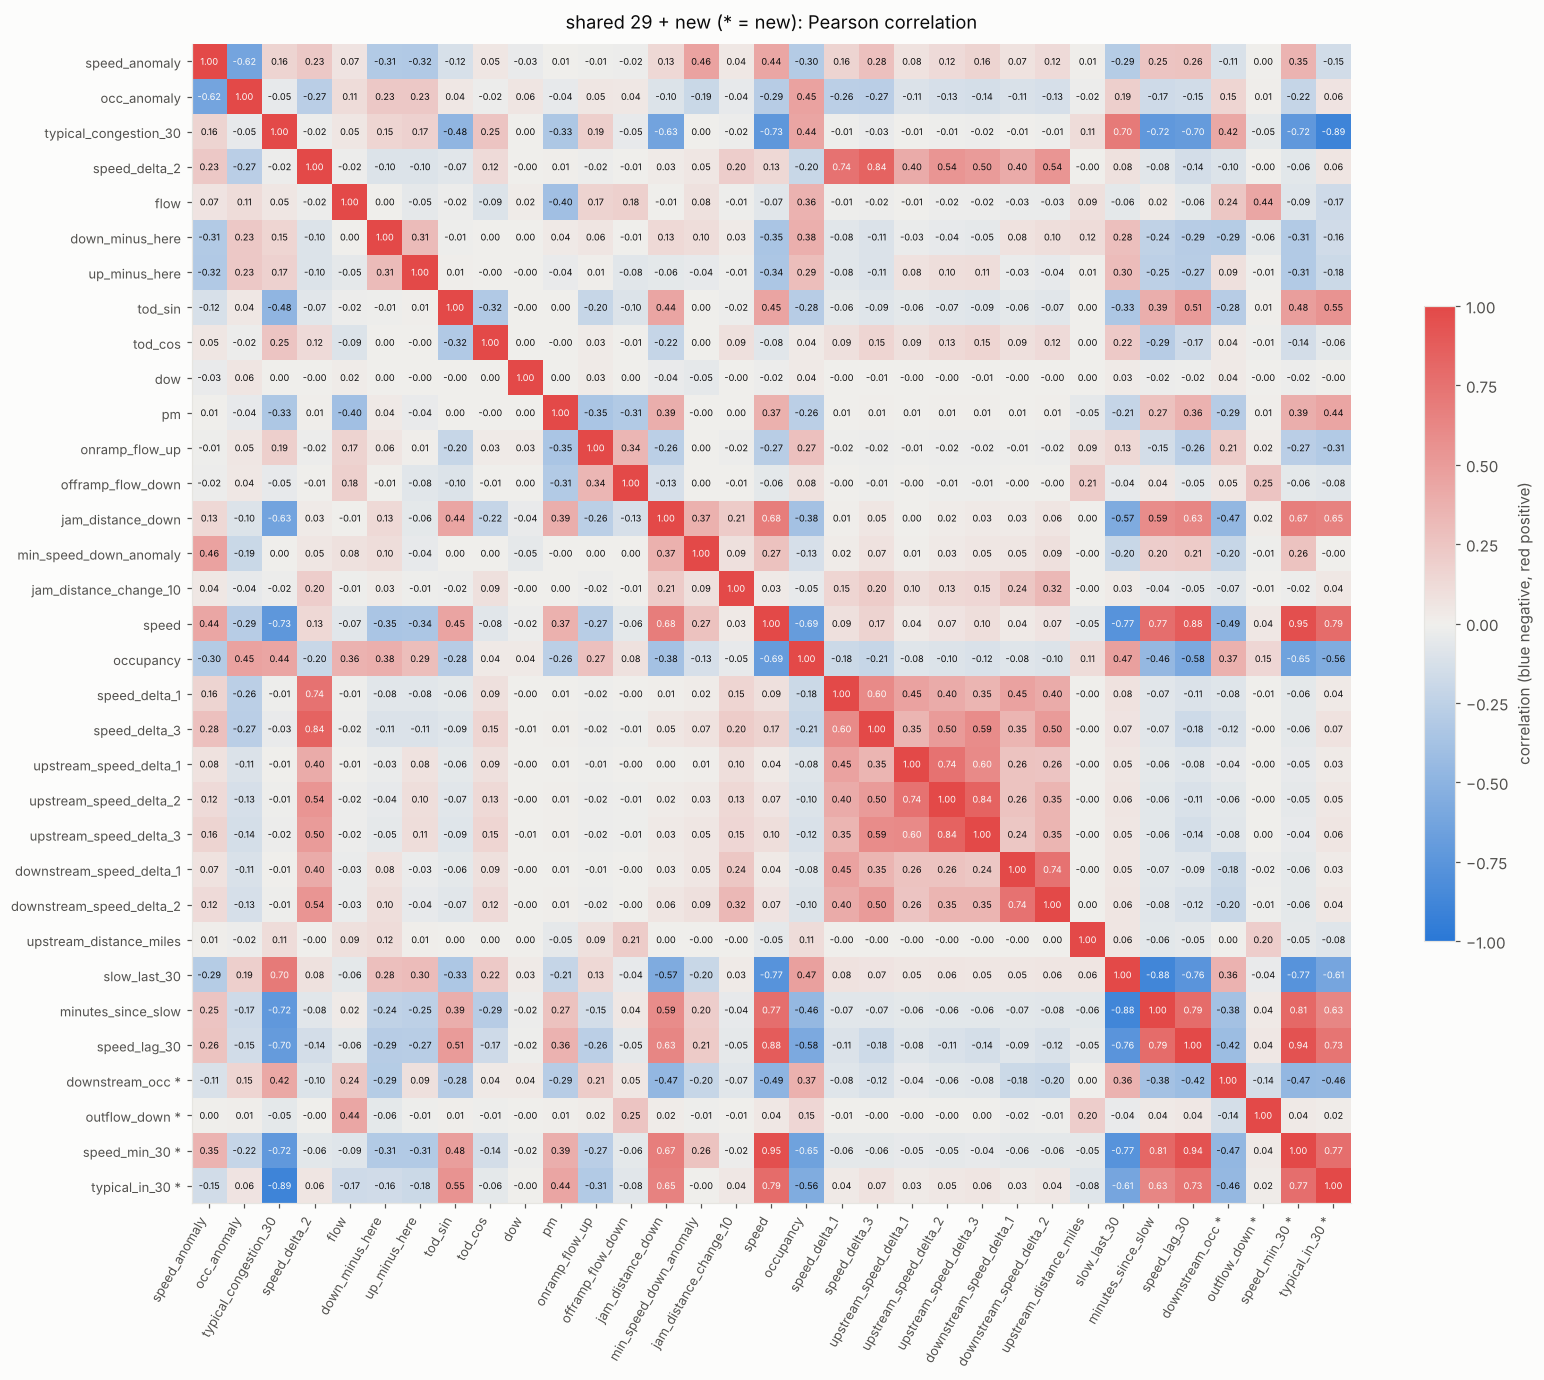

In [9]:
blue_gray_red = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", "#e34948"])

pearson = corr["shared 29 + new"][0]
features = list(pearson.columns)
fig, ax = plt.subplots(figsize=(17, 15))
ax.imshow(pearson.values, cmap=blue_gray_red, vmin=-1, vmax=1)
for i in range(len(features)):
    for j in range(len(features)):
        r = pearson.values[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=6, color=BACKGROUND if abs(r) >= 0.6 else INK)
labels = [f"{f} *" if ORIGIN[f] == "new" else f for f in features]
ax.set_xticks(range(len(features)), labels, rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(features)), labels, fontsize=8.5)
ax.grid(False)
ax.set_title("shared 29 + new (* = new): Pearson correlation", pad=10)
fig.colorbar(ax.images[0], ax=ax, shrink=0.5, label="correlation (blue negative, red positive)")
plt.show()

In [10]:
print("Most correlated pairs, shared 29 + new")
display(most_correlated_pairs(*corr["shared 29 + new"]))
vif_table = {name: values.sort_values(ascending=False).round(1).rename_axis("feature").reset_index(name="VIF")
             for name, values in vif.items()}
pd.concat(vif_table, axis=1).head(15)

Most correlated pairs, shared 29 + new


,feature 1,feature 2,Spearman,Pearson,largest |r|
0,speed,speed_min_30,0.95,0.95,0.95
1,speed_lag_30,speed_min_30,0.93,0.94,0.94
2,typical_congestion_30,typical_in_30,-0.76,-0.89,0.89
3,slow_last_30,minutes_since_slow,-0.88,-0.88,0.88
4,speed,speed_lag_30,0.88,0.88,0.88
5,upstream_speed_delta_2,upstream_speed_delta_3,0.75,0.84,0.84
6,speed_delta_2,speed_delta_3,0.75,0.84,0.84
7,minutes_since_slow,speed_min_30,0.57,0.81,0.81
8,speed,typical_in_30,0.77,0.79,0.79
9,minutes_since_slow,speed_lag_30,0.57,0.79,0.79


original 16                      shared 29                 shared 29 + new      
                   feature  VIF                   feature   VIF                   feature   VIF
0        jam_distance_down  3.6                     speed  30.4                     speed  68.7
1    typical_congestion_30  2.8              speed_lag_30   9.9              speed_min_30  36.3
2            speed_anomaly  2.5     typical_congestion_30   8.9             typical_in_30  24.2
3                       pm  2.2             speed_anomaly   6.8     typical_congestion_30  12.0
4              occ_anomaly  1.8        minutes_since_slow   6.5              speed_lag_30  11.6
5                  tod_sin  1.7              slow_last_30   6.4             speed_anomaly   9.8
6   min_speed_down_anomaly  1.7             speed_delta_2   5.7        minutes_since_slow   7.5
7          down_minus_here  1.5             speed_delta_3   5.3              slow_last_30   7.2
8                     flow  1.5    upstream_speed_delta_2   5.3             speed_delta_3   5.7
9        offramp_flow_down  1.3         jam_distance_down   4.5             speed_delta_2   5.7
10          onramp_flow_up  1.3    upstream_speed_delta_3   4.2    upstream_speed_delta_2   5.3
11           up_minus_here  1.3                 occupancy   3.1         jam_distance_down   4.7
12           speed_delta_2  1.2  downstream_speed_delta_2   2.9    upstream_speed_delta_3   4.2
13                 tod_cos  1.2             speed_delta_1   2.8                 occupancy   3.3
14  jam_distance_change_10  1.2                        pm   2.6  downstream_speed_delta_2   2.9

## 5. Do three different methods agree a feature matters? (check a)
Checks (a)–(c) each run once per **selection quarter** (2024 Q1–Q3). In each, the fold-dependent features are rebuilt from that fold's training
days, then a random sample of `FIT_SAMPLE` training rows (outcome measured, as the team trains) and all of the quarter's **onset rows** (scored,
not congested now: the rows *AP, onsets* uses) are kept.

In [11]:
all_folds = list(sf.folds(df))
selection_folds = all_folds[:SELECTION_QUARTERS]
quarter_names = [fold.name for fold in selection_folds]
keep_columns = CANDIDATES + ["y", "timestamp", "station"]

windows = {}                                           # quarter -> (training sample, onset rows)
for number, fold in enumerate(selection_folds, 1):
    sf.add_typical_features(df, fold.train)
    train = df.loc[fold.train & df["y_known"], keep_columns]
    train = train.sample(min(FIT_SAMPLE, len(train)), random_state=number - 1).sort_values("timestamp").reset_index(drop=True)
    onset_rows = fold.val & df["y_known"] & ~df["congested_now"] & df["real"]
    val = df.loc[onset_rows, keep_columns].reset_index(drop=True)
    windows[fold.name] = (train, val)
    print(f"quarter {number} ({fold.name}) | {len(train):,} training rows ({train['y'].mean():.1%} congested within 30 min) | "
          f"{len(val):,} onset rows ({val['y'].mean():.1%} become congested = AP of random guessing)")

quarter 1 (2024-01 to 2024-03) | 300,000 training rows (13.5% congested within 30 min) | 289,603 onset rows (4.9% become congested = AP of random guessing)


quarter 2 (2024-04 to 2024-06) | 300,000 training rows (13.7% congested within 30 min) | 265,616 onset rows (4.6% become congested = AP of random guessing)


quarter 3 (2024-07 to 2024-09) | 300,000 training rows (13.7% congested within 30 min) | 248,438 onset rows (5.0% become congested = AP of random guessing)


Three methods that judge a feature in different ways each name their top `TOP_N`:
- **mutual information:** how much knowing the feature reduces uncertainty about the outcome, on its own (any shape of relationship);
- **L1 logistic regression:** a linear model that sets the weights of unhelpful features to zero (inputs standardized, regularization chosen
  with time-ordered cross-validation);
- **random forest importance:** how much the forest's splits on the feature improve purity.

Mutual information and the forest need complete inputs, so blanks are filled with the training median for these methods only.
A feature is **picked** in a quarter if at least 2 of the 3 methods name it, and **passes (a)** if it's picked in at least `MIN_QUARTERS` quarters.

In [12]:
def vote(train, seed=0):
    # How many of the three methods (0-3) name each feature in their top TOP_N.
    filled = pd.DataFrame(SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(train[CANDIDATES]),
                          columns=CANDIDATES)
    y = train["y"].to_numpy()

    small = np.random.default_rng(seed).choice(len(train), min(VOTE_SAMPLE, len(train)), replace=False)
    small.sort()                                       # keep time order for the L1 cross-validation
    mi = pd.Series(mutual_info_classif(filled.iloc[small], y[small], random_state=seed), index=CANDIDATES)

    scaled = StandardScaler().fit_transform(filled.iloc[small])
    l1 = LogisticRegressionCV(Cs=np.logspace(-3, 0, 6), penalty="l1", solver="liblinear", cv=TimeSeriesSplit(n_splits=3),
                              scoring="average_precision", max_iter=1000, n_jobs=-1, random_state=seed).fit(scaled, y[small])
    l1_weight = pd.Series(np.abs(l1.coef_[0]), index=CANDIDATES)

    forest = RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=20, max_samples=min(50_000, len(train)),
                                    n_jobs=-1, random_state=seed).fit(filled, y)
    forest_importance = pd.Series(forest.feature_importances_, index=CANDIDATES)

    tops = [set(mi.nlargest(TOP_N).index), set(l1_weight[l1_weight > 0].nlargest(TOP_N).index),
            set(forest_importance.nlargest(TOP_N).index)]
    return pd.Series([sum(f in top for top in tops) for f in CANDIDATES], index=CANDIDATES)


start = time.time()
votes = pd.DataFrame({name: vote(windows[name][0], seed=k) for k, name in enumerate(quarter_names)})
check_a = (votes >= 2).sum(axis=1)
pass_a = check_a >= MIN_QUARTERS
print(f"Check (a): {int(pass_a.sum())} of {len(CANDIDATES)} features pass | {time.time() - start:.0f}s")

table_a = votes.copy()
table_a["mean methods"] = votes.mean(axis=1).round(2)
table_a["quarters picked"] = check_a.astype(str) + f" of {SELECTION_QUARTERS}"
table_a["verdict"] = np.where(pass_a, "passes", "fails")
table_a["from"] = table_a.index.map(ORIGIN)
table_a.sort_values("mean methods", ascending=False)

Check (a): 13 of 33 features pass | 104s


,2024-01 to 2024-03,2024-04 to 2024-06,2024-07 to 2024-09,mean methods,quarters picked,verdict,from
typical_congestion_30,3,3,3,3.00,3 of 3,passes,original 16
typical_in_30,3,3,3,3.00,3 of 3,passes,new
slow_last_30,3,3,3,3.00,3 of 3,passes,added 31 Oct
minutes_since_slow,3,3,3,3.00,3 of 3,passes,added 31 Oct
tod_sin,3,2,3,2.67,3 of 3,passes,original 16
downstream_occ,2,3,2,2.33,3 of 3,passes,new
speed_lag_30,2,3,2,2.33,3 of 3,passes,added 31 Oct
speed_anomaly,2,2,2,2.00,3 of 3,passes,original 16
jam_distance_down,2,2,2,2.00,3 of 3,passes,original 16
speed,2,2,2,2.00,3 of 3,passes,added 31 Oct


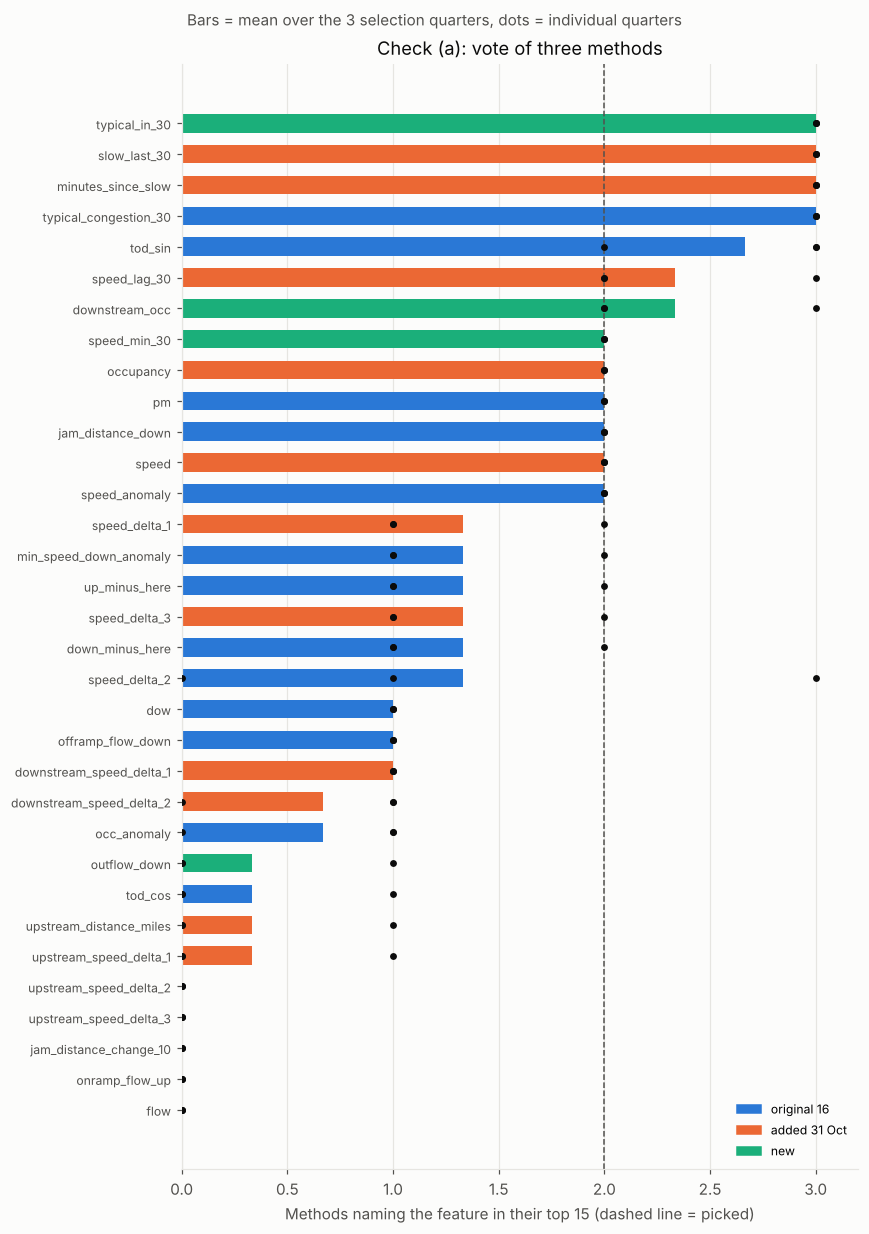

In [13]:
def bars_with_dots(ax, values, quarters, colors, line=None):
    # Horizontal bars = mean over the selection quarters, dots = individual quarters (as in feature_selection.ipynb).
    positions = np.arange(len(values))
    ax.barh(positions, values.values, height=0.6, color=colors)
    for y, feature in zip(positions, values.index):
        ax.scatter(quarters.loc[feature].astype(float), np.full(quarters.shape[1], y), s=12, color=INK, zorder=3)
    if line is not None:
        ax.axvline(line, color=INK2, linewidth=1, linestyle="--")
    ax.set_yticks(positions, values.index, fontsize=8)
    ax.grid(axis="y", visible=False)


order = table_a.sort_values("mean methods").index
fig, ax = plt.subplots(figsize=(8, 0.3 * len(order) + 1.5))
bars_with_dots(ax, votes.mean(axis=1)[order], votes.loc[order], [ORIGIN_COLORS[ORIGIN[f]] for f in order], line=2)
ax.set_xlabel("Methods naming the feature in their top 15 (dashed line = picked)")
ax.set_xlim(0, 3.2)
ax.set_title("Check (a): vote of three methods")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ORIGIN_COLORS.values()], list(ORIGIN_COLORS), loc="lower right", fontsize=8)
plt.suptitle("Bars = mean over the 3 selection quarters, dots = individual quarters", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

## 6. Does a feature beat random noise? (check b)
The shadow-feature test (Boruta / GrootCV style). Every feature gets a **shuffled copy**: same values, random order, so by construction it carries
no signal. LightGBM (pruned trees, depth 6, as recommended for this test) is trained on the fold's training rows with real and shuffled features
together. Importance = mean |SHAP value| on `SHAP_ROWS` of the quarter's onset rows (LightGBM computes SHAP values itself).

The chart shows each feature's importance **divided by the best shuffled copy's**: above 1 = more useful than the best pure-noise feature.
A feature **passes (b)** if it's above 1 in at least `MIN_QUARTERS` quarters. No top-N cut-off is needed.

In [14]:
def shadow_ratio(train, val, seed):
    # Each feature's mean |SHAP| divided by the best shuffled copy's (above 1 = beats every shadow).
    rng = np.random.default_rng(seed)
    shadow_names = ["shadow_" + f for f in CANDIDATES]

    def with_shadows(rows):
        real = rows[CANDIDATES].reset_index(drop=True)
        shadows = pd.DataFrame({s: rng.permutation(real[f].to_numpy()) for f, s in zip(CANDIDATES, shadow_names)})
        return pd.concat([real, shadows], axis=1)

    model = LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=31, max_depth=6, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, verbose=-1, random_state=seed)
    model.fit(with_shadows(train), train["y"])
    rows = val.sample(min(SHAP_ROWS, len(val)), random_state=seed)
    shap_values = model.predict(with_shadows(rows), pred_contrib=True)[:, :-1]          # last column = baseline
    importance = pd.Series(np.abs(shap_values).mean(axis=0), index=CANDIDATES + shadow_names)
    return importance[CANDIDATES] / importance[shadow_names].max()


if LGBMClassifier is not None:
    start = time.time()
    ratios = pd.DataFrame({name: shadow_ratio(*windows[name], seed=k) for k, name in enumerate(quarter_names)})
    check_b = (ratios > 1).sum(axis=1)
    pass_b = check_b >= MIN_QUARTERS
    print(f"Check (b): {int(pass_b.sum())} of {len(CANDIDATES)} features pass | {time.time() - start:.0f}s")
    table_b = ratios.round(2)
    table_b["mean"] = ratios.mean(axis=1).round(2)
    table_b["std across quarters"] = ratios.std(axis=1).round(2)
    table_b["quarters above noise"] = check_b.astype(str) + f" of {SELECTION_QUARTERS}"
    table_b["verdict"] = np.where(pass_b, "passes", "fails")
    table_b["from"] = table_b.index.map(ORIGIN)
    display(table_b.sort_values("mean", ascending=False))
else:
    ratios = None
    check_b = pd.Series(0, index=CANDIDATES)
    pass_b = pd.Series(True, index=CANDIDATES)        # without LightGBM, check (b) doesn't filter anything
    print("Check (b) skipped: lightgbm is not installed")

Check (b): 23 of 33 features pass | 74s


,2024-01 to 2024-03,2024-04 to 2024-06,2024-07 to 2024-09,mean,std across quarters,quarters above noise,verdict,from
typical_congestion_30,147.16,61.54,94.79,101.16,43.17,3 of 3,passes,original 16
speed,98.99,37.65,62.10,66.25,30.88,3 of 3,passes,added 31 Oct
typical_in_30,35.28,14.99,17.83,22.70,10.99,3 of 3,passes,new
speed_min_30,19.55,11.58,12.38,14.50,4.39,3 of 3,passes,new
speed_anomaly,22.32,6.52,10.28,13.04,8.26,3 of 3,passes,original 16
min_speed_down_anomaly,14.69,7.31,11.39,11.13,3.70,3 of 3,passes,original 16
occupancy,17.27,4.93,5.91,9.37,6.86,3 of 3,passes,added 31 Oct
downstream_occ,15.66,2.23,5.45,7.78,7.01,3 of 3,passes,new
offramp_flow_down,13.18,1.97,7.19,7.45,5.61,3 of 3,passes,original 16
tod_cos,9.49,4.76,6.25,6.83,2.42,3 of 3,passes,original 16


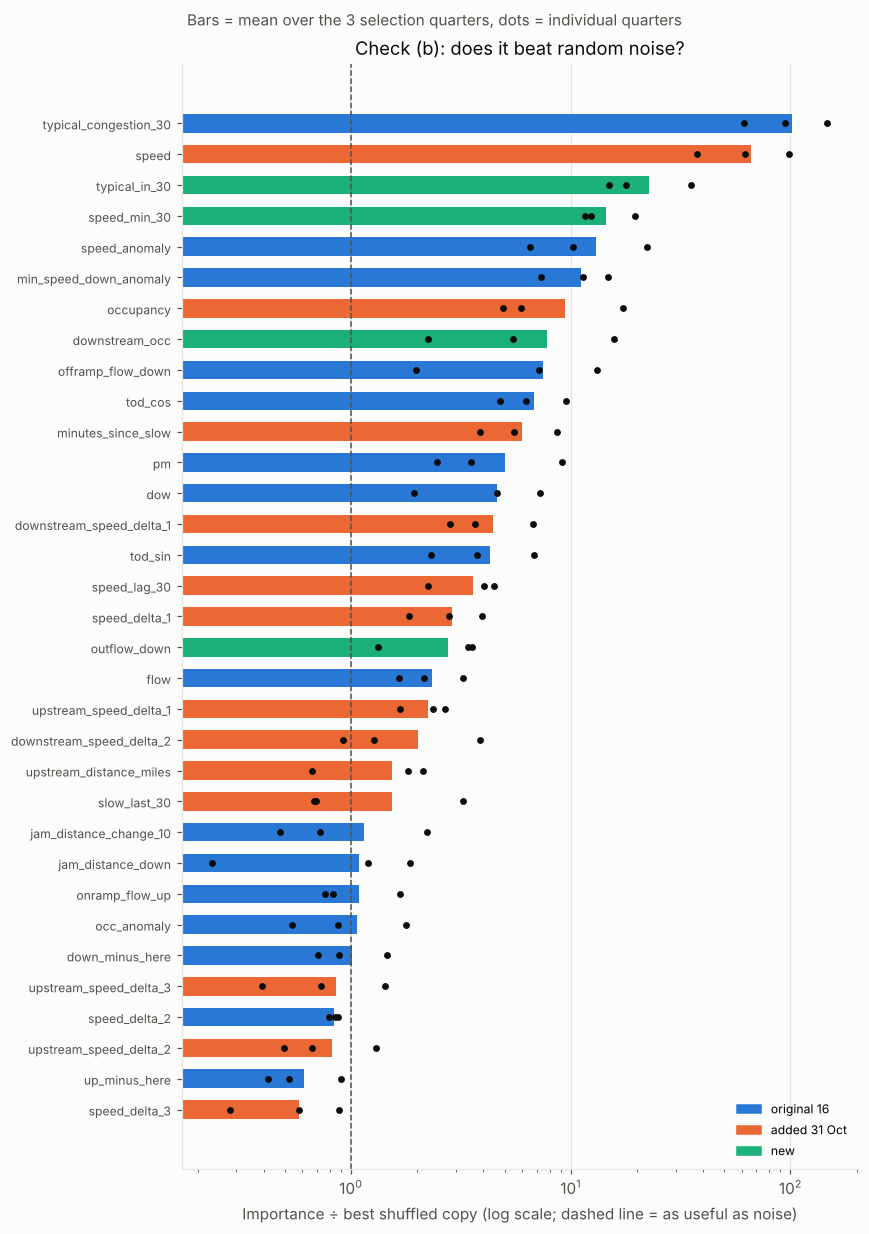

In [15]:
if ratios is not None:
    order = ratios.mean(axis=1).sort_values().index
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(order) + 1.5))
    bars_with_dots(ax, ratios.mean(axis=1)[order], ratios.loc[order], [ORIGIN_COLORS[ORIGIN[f]] for f in order], line=1)
    ax.set_xscale("log")
    ax.set_xlabel("Importance ÷ best shuffled copy (log scale; dashed line = as useful as noise)")
    ax.set_title("Check (b): does it beat random noise?")
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ORIGIN_COLORS.values()], list(ORIGIN_COLORS),
              loc="lower right", fontsize=8)
    plt.suptitle("Bars = mean over the 3 selection quarters, dots = individual quarters", color=INK2, fontsize=10)
    plt.tight_layout()
    plt.show()

## 7. Which features earn their place? (check c: drop and refit)
Importance scores split credit unpredictably between correlated features, so the direct test is the one `feature_selection.ipynb` uses: refit
without a feature and see how much *AP, onsets* falls, in every selection quarter. Each difference is paired (same quarter, same rows).

- **Candidates** = features that pass (a) or (b).
- **Families:** candidates whose correlations with each other are *all* above `FAMILY_CORR` (complete-linkage clustering, on the first
  quarter's training rows, so no later data affects the choice).
- **Tested** = every member of a family, and every candidate that passed only one of (a) and (b). A candidate that passed both and has no close
  relative is kept without testing.

**Rule:** **keep** a tested feature if removing it lowers AP in at least `MIN_QUARTERS` of the 3 quarters (and on average);
otherwise it's a **drop candidate**. A family always keeps its strongest member (the one whose removal costs the most AP), so its information is
never dropped as a whole. The faster `CHECK_PARAMS` version of the team's model is used here.

In [16]:
candidates = [f for f in CANDIDATES if pass_a[f] or pass_b[f]]
both = [f for f in candidates if pass_a[f] and pass_b[f]]

first_quarter_corr = windows[quarter_names[0]][0][candidates].corr().abs().fillna(0)
distance = 1 - first_quarter_corr.to_numpy()
np.fill_diagonal(distance, 0)
cluster = fcluster(linkage(squareform(distance, checks=False), method="complete"), t=1 - FAMILY_CORR, criterion="distance")
families = [[f for f, label in zip(candidates, cluster) if label == k] for k in pd.unique(cluster)]
family_of = {f: fam for fam in families for f in fam}
tested = [f for f in candidates if len(family_of[f]) > 1 or f not in both]

print(f"{len(candidates)} candidates: {len(both)} pass both checks, {len(candidates) - len(both)} pass one | {len(tested)} tested")
for fam in families:
    if len(fam) > 1:
        print("   family:", ", ".join(fam))


def ap_on(train, val, features):
    model = HistGradientBoostingClassifier(**CHECK_PARAMS).fit(train[features], train["y"])
    return average_precision_score(val["y"], model.predict_proba(val[features])[:, 1])


lost = {}
for number, name in enumerate(quarter_names, 1):
    start = time.time()
    train, val = windows[name]
    base = ap_on(train, val, candidates)
    lost[name] = pd.Series({f: base - ap_on(train, val, [g for g in candidates if g != f]) for f in tested})
    print(f"quarter {number} ({name}) | AP onsets with all {len(candidates)} candidates {base:.3f} | {time.time() - start:.0f}s")
drops = pd.DataFrame(lost)
helped = (drops[quarter_names] > 0).sum(axis=1)
mean_lost = drops[quarter_names].mean(axis=1)

table_c = pd.DataFrame({"mean AP lost": mean_lost.round(4), "std across quarters": drops[quarter_names].std(axis=1).round(4),
                        "quarters where it helped": helped.astype(str) + f" of {SELECTION_QUARTERS}",
                        "verdict": np.where((helped >= MIN_QUARTERS) & (mean_lost > 0), "keep", "drop candidate"),
                        "family": [", ".join(family_of[f]) if len(family_of[f]) > 1 else "" for f in drops.index],
                        "from": drops.index.map(ORIGIN)})
for fam in families:                                   # a family always keeps its strongest member
    if len(fam) > 1:
        strongest = mean_lost[fam].idxmax()
        if table_c.loc[strongest, "verdict"] != "keep":
            table_c.loc[strongest, "verdict"] = "keep (strongest in family)"
table_c.sort_values("mean AP lost", ascending=False)

24 candidates: 12 pass both checks, 12 pass one | 18 tested
   family: typical_congestion_30, typical_in_30
   family: speed, speed_lag_30, speed_min_30
   family: slow_last_30, minutes_since_slow


quarter 1 (2024-01 to 2024-03) | AP onsets with all 24 candidates 0.750 | 124s


quarter 2 (2024-04 to 2024-06) | AP onsets with all 24 candidates 0.779 | 124s


quarter 3 (2024-07 to 2024-09) | AP onsets with all 24 candidates 0.752 | 123s


,mean AP lost,std across quarters,quarters where it helped,verdict,family,from
minutes_since_slow,0.0161,0.0283,2 of 3,keep,"slow_last_30, minutes_since_slow",added 31 Oct
tod_cos,0.0059,0.0084,3 of 3,keep,,original 16
speed,0.0049,0.0017,3 of 3,keep,"speed, speed_lag_30, speed_min_30",added 31 Oct
upstream_speed_delta_1,0.0038,0.0009,3 of 3,keep,,added 31 Oct
flow,0.0033,0.0003,3 of 3,keep,,original 16
min_speed_down_anomaly,0.0016,0.0014,2 of 3,keep,,original 16
speed_min_30,0.0012,0.0018,2 of 3,keep,"speed, speed_lag_30, speed_min_30",new
dow,0.0012,0.0008,3 of 3,keep,,original 16
typical_congestion_30,0.0011,0.0009,3 of 3,keep,"typical_congestion_30, typical_in_30",original 16
speed_delta_1,0.0011,0.0032,2 of 3,keep,,added 31 Oct


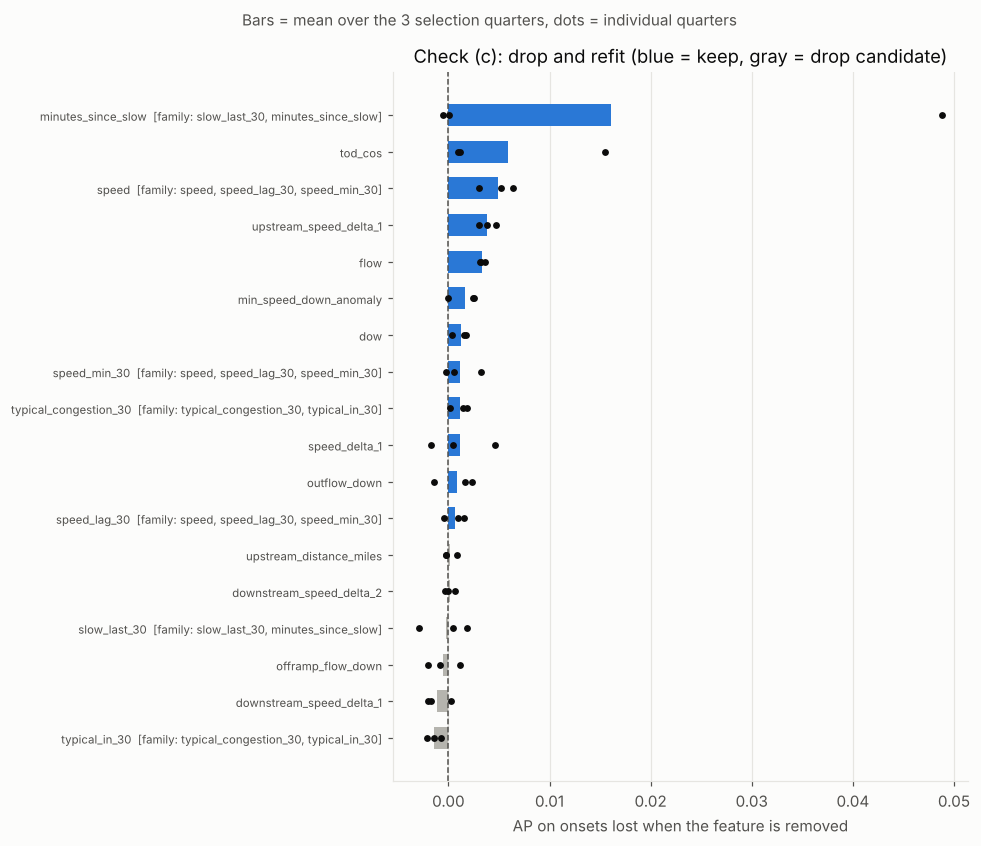

In [17]:
order = mean_lost.sort_values().index
fig, ax = plt.subplots(figsize=(9, 0.35 * len(order) + 1.5))
colors = [BLUE if table_c.loc[f, "verdict"].startswith("keep") else GRAY for f in order]
bars_with_dots(ax, mean_lost[order], drops.loc[order, quarter_names], colors, line=0)
ax.set_yticks(range(len(order)), [f"{f}  [family: {table_c.loc[f, 'family']}]" if table_c.loc[f, "family"] else f for f in order],
              fontsize=7.5)
ax.set_xlabel("AP on onsets lost when the feature is removed")
ax.set_title("Check (c): drop and refit (blue = keep, gray = drop candidate)")
plt.suptitle("Bars = mean over the 3 selection quarters, dots = individual quarters", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

## 8. The selected set
Candidates that passed both (a) and (b) without a close relative, plus every tested feature marked **keep**.

In [18]:
keep = set(table_c.index[table_c["verdict"].str.startswith("keep")])
selected = [f for f in CANDIDATES if f in candidates and ((f in both and len(family_of[f]) == 1) or f in keep)]

checks = pd.DataFrame({"from": pd.Series(ORIGIN),
                       "(a) quarters picked": check_a.astype(str) + f" of {SELECTION_QUARTERS}",
                       "(b) quarters above noise": check_b.astype(str) + f" of {SELECTION_QUARTERS}",
                       "(c)": [table_c.loc[f, "verdict"] if f in table_c.index else ("not needed" if f in candidates else "")
                               for f in CANDIDATES],
                       "selected": [f in selected for f in CANDIDATES]}).loc[CANDIDATES]
print(f"{len(selected)} selected: " + ", ".join(f"{n} {o}" for o, n in checks.loc[selected, "from"].value_counts().items()))
print("Not selected:", ", ".join(f for f in CANDIDATES if f not in selected))
checks.sort_values(["selected", "from"], ascending=[False, True])

18 selected: 9 original 16, 6 added 31 Oct, 3 new
Not selected: occ_anomaly, speed_delta_2, down_minus_here, up_minus_here, onramp_flow_up, offramp_flow_down, jam_distance_change_10, speed_delta_3, upstream_speed_delta_2, upstream_speed_delta_3, downstream_speed_delta_1, downstream_speed_delta_2, upstream_distance_miles, slow_last_30, typical_in_30


,from,(a) quarters picked,(b) quarters above noise,(c),selected
speed,added 31 Oct,3 of 3,3 of 3,keep,True
occupancy,added 31 Oct,3 of 3,3 of 3,not needed,True
speed_delta_1,added 31 Oct,1 of 3,3 of 3,keep,True
upstream_speed_delta_1,added 31 Oct,0 of 3,3 of 3,keep,True
minutes_since_slow,added 31 Oct,3 of 3,3 of 3,keep,True
speed_lag_30,added 31 Oct,3 of 3,3 of 3,keep,True
downstream_occ,new,3 of 3,3 of 3,not needed,True
outflow_down,new,0 of 3,3 of 3,keep,True
speed_min_30,new,3 of 3,3 of 3,keep,True
speed_anomaly,original 16,3 of 3,3 of 3,not needed,True


## 9. Walk-forward validation (six quarterly folds)
For each validation quarter: rebuild the fold-dependent features from that fold's training days (`sf.add_typical_features`), train the team's
boosted trees (`TREE_PARAMS`) on up to `TRAIN_SAMPLE` rows whose outcome was measured, and score the quarter with `sf.score`. Every feature set is
scored on the same rows, so the differences between sets are paired. **The last three quarters were not used for choosing.**
This is the slow part (about 35 minutes).

In [19]:
FEATURE_SETS = {
    "original 16": SHARED_16,
    "shared 29": SHARED_NOW,
    "shared 29 + new": CANDIDATES,
    "selected": selected,
}
for name, features in FEATURE_SETS.items():
    print(f"{name:<18} {len(features):>2} features | boosted trees | trained on measured labels")

results = []                       # one row per fold and model
val_predictions = []               # validation rows with every model's probabilities, for sections 10-11
last_models = {}                   # models from the last fold, for section 12

for number, fold in enumerate(all_folds, 1):
    sf.add_typical_features(df, fold.train)
    train = df.loc[fold.train & df["y_known"], CANDIDATES + ["y"]]
    if TRAIN_SAMPLE and len(train) > TRAIN_SAMPLE:
        train = train.sample(TRAIN_SAMPLE, random_state=0)
    val = df[fold.val]
    predictions = val[sf.KEY + ["date", "y", "y_known", "congested_now", "real", "onset"]].copy()

    baselines = {
        "same as now": val["congested_now"].astype(float).to_numpy(),
        "typical for this time": val["typical_congestion_30"].fillna(0).to_numpy(),
    }
    for name, probability in baselines.items():
        results.append({"fold": fold.name, "model": name, **sf.score(val, probability)})
        predictions[name] = probability

    for name, features in FEATURE_SETS.items():
        start = time.time()
        model = HistGradientBoostingClassifier(**TREE_PARAMS).fit(train[features], train["y"])
        probability = model.predict_proba(val[features])[:, 1]
        result = {"fold": fold.name, "model": name, **sf.score(val, probability)}
        results.append(result)
        predictions[name] = probability.astype("float32")
        last_models[name] = model
        print(f"fold {number} ({fold.name}) | {name:<16} AP onsets {result['AP, onsets']:.3f} | "
              f"caught {result['caught ≥15 min']:.0%} | false alarms/day {result['false alarms / day']:.1f} | "
              f"{time.time() - start:.0f}s")
    val_predictions.append(predictions)
last_train, last_val = train, val                      # the last fold, for section 12

results = pd.DataFrame(results)
MODEL_ORDER = ["same as now", "typical for this time"] + list(FEATURE_SETS)
METRICS = ["AP, onsets", "AP, all", "Brier", "caught ≥15 min", "false alarms / day", "wrong-alert hours / day",
           "alerts right", "median lead (min)"]
summary = results.groupby("model")[METRICS].agg(["mean", "std"]).reindex(MODEL_ORDER).round(3)
summary

original 16        16 features | boosted trees | trained on measured labels
shared 29          29 features | boosted trees | trained on measured labels
shared 29 + new    33 features | boosted trees | trained on measured labels
selected           18 features | boosted trees | trained on measured labels


fold 1 (2024-01 to 2024-03) | original 16      AP onsets 0.739 | caught 69% | false alarms/day 38.7 | 23s


fold 1 (2024-01 to 2024-03) | shared 29        AP onsets 0.761 | caught 70% | false alarms/day 37.9 | 32s


fold 1 (2024-01 to 2024-03) | shared 29 + new  AP onsets 0.761 | caught 71% | false alarms/day 38.8 | 34s


fold 1 (2024-01 to 2024-03) | selected         AP onsets 0.760 | caught 69% | false alarms/day 38.7 | 23s


fold 2 (2024-04 to 2024-06) | original 16      AP onsets 0.765 | caught 64% | false alarms/day 30.1 | 30s


... (16 outputs left out)

fold 6 (2025-04 to 2025-06) | shared 29        AP onsets 0.767 | caught 61% | false alarms/day 30.3 | 79s


fold 6 (2025-04 to 2025-06) | shared 29 + new  AP onsets 0.766 | caught 61% | false alarms/day 30.0 | 90s


fold 6 (2025-04 to 2025-06) | selected         AP onsets 0.767 | caught 61% | false alarms/day 30.7 | 58s


AP, onsets        AP, all         Brier        caught ≥15 min        false alarms / day        wrong-alert hours / day         \
                            mean    std    mean    std   mean    std           mean    std               mean    std                    mean    std   
model                                                                                                                                                 
same as now                0.050  0.003   0.723  0.015  0.049  0.002          0.000  0.000             22.765  1.742                   1.897  0.145   
typical for this time      0.563  0.039   0.894  0.016  0.040  0.004          0.541  0.064             18.067  4.883                   8.979  2.941   
original 16                0.748  0.012   0.963  0.004  0.023  0.001          0.626  0.039             31.097  3.928                   5.360  1.024   
shared 29                  0.767  0.011   0.966  0.003  0.022  0.001          0.640  0.031             31.096  3.381                   5.044  0.873   
shared 29 + new            0.762  0.014   0.965  0.003  0.022  0.001          0.640  0.037             31.477  3.637                   5.110  0.914   
selected                   0.763  0.012   0.966  0.003  0.022  0.001          0.636  0.030             31.852  3.389                   5.178  0.890   

                      alerts right        median lead (min)         
                              mean    std              mean    std  
model                                                               
same as now                  0.957  0.003               NaN    NaN  
typical for this time        0.842  0.037            30.000  0.000  
original 16                  0.908  0.011            24.167  2.041  
shared 29                    0.913  0.010            24.167  2.041  
shared 29 + new              0.912  0.010            24.167  2.041  
selected                     0.911  0.010            24.167  2.041

In [20]:
per_fold = results.pivot_table(index="fold", columns="model", values="AP, onsets").reindex(columns=MODEL_ORDER).round(4)
not_used = ~per_fold.index.isin(quarter_names)


def compare(a, b, label):
    for rows, which in [(slice(None), "all 6 quarters"), (not_used, "last 3, not used for choosing")]:
        difference = (per_fold[a] - per_fold[b])[rows]
        print(f"{label} ({which}): mean {difference.mean():+.4f}, range {difference.min():+.4f} to {difference.max():+.4f}, "
              f"better in {int((difference > 0).sum())} of {len(difference)}")


compare("shared 29", "original 16", "Shared 29 minus original 16")
compare("shared 29 + new", "shared 29", "Adding the 4 new features to the shared 29")
compare("selected", "shared 29", "Selected minus shared 29")
per_fold.assign(**{"used for choosing": ~not_used})

Shared 29 minus original 16 (all 6 quarters): mean +0.0182, range +0.0144 to +0.0225, better in 6 of 6
Shared 29 minus original 16 (last 3, not used for choosing): mean +0.0163, range +0.0144 to +0.0200, better in 3 of 3
Adding the 4 new features to the shared 29 (all 6 quarters): mean -0.0047, range -0.0277 to +0.0033, better in 1 of 6
Adding the 4 new features to the shared 29 (last 3, not used for choosing): mean -0.0097, range -0.0277 to -0.0006, better in 0 of 3
Selected minus shared 29 (all 6 quarters): mean -0.0031, range -0.0066 to +0.0002, better in 1 of 6
Selected minus shared 29 (last 3, not used for choosing): mean -0.0033, range -0.0064 to +0.0002, better in 1 of 3


model,same as now,typical for this time,original 16,shared 29,shared 29 + new,selected,used for choosing
fold,,,,,,,
2024-01 to 2024-03,0.0486,0.5626,0.7389,0.7614,0.7611,0.7596,True
2024-04 to 2024-06,0.0462,0.5658,0.7653,0.7837,0.7870,0.7831,True
2024-07 to 2024-09,0.0502,0.5753,0.7381,0.7574,0.7550,0.7508,True
2024-10 to 2024-12,0.0551,0.4925,0.7606,0.7752,0.7475,0.7688,False
2025-01 to 2025-03,0.0496,0.5710,0.7408,0.7552,0.7546,0.7515,False
2025-04 to 2025-06,0.0483,0.6106,0.7469,0.7669,0.7662,0.7671,False


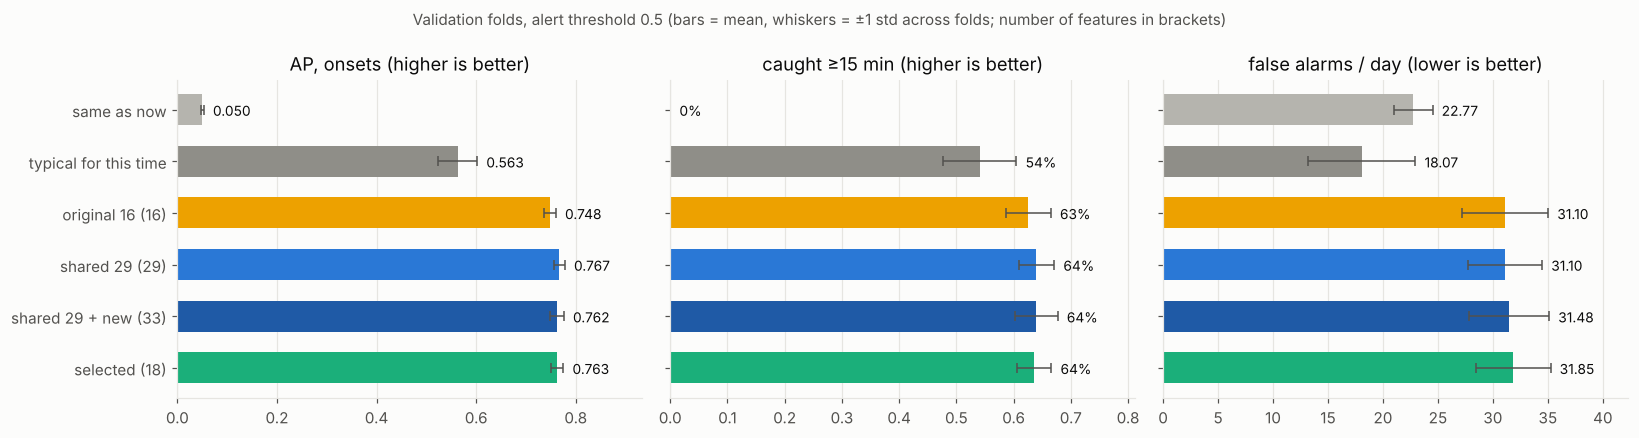

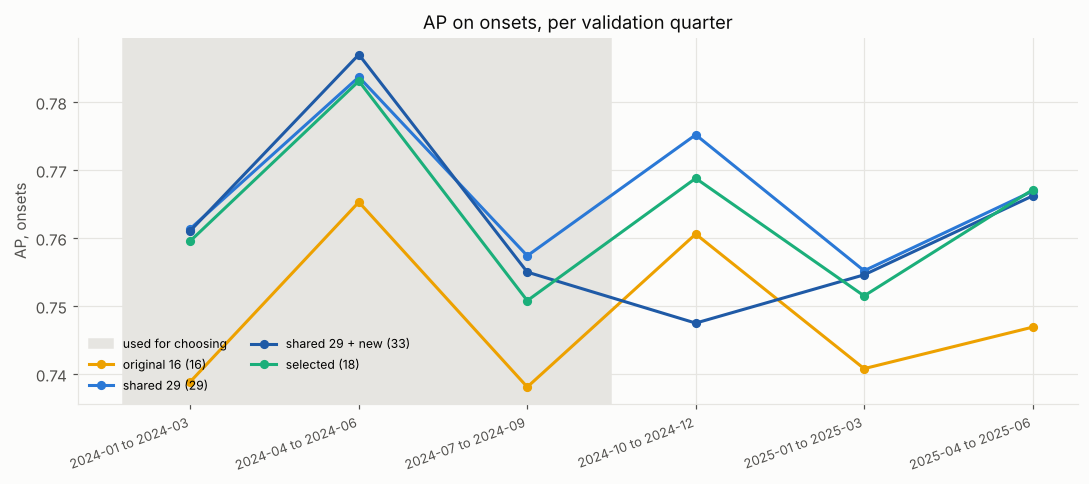

In [21]:
COLORS = {"same as now": GRAY, "typical for this time": DARK_GRAY, "original 16": YELLOW, "shared 29": BLUE,
          "shared 29 + new": "#1f5aa6", "selected": AQUA}
panels = [("AP, onsets", "higher"), ("caught ≥15 min", "higher"), ("false alarms / day", "lower")]

fig, axes = plt.subplots(1, 3, figsize=(15, 0.42 * len(MODEL_ORDER) + 1.5), sharey=True)
positions = np.arange(len(MODEL_ORDER))[::-1]
for ax, (metric, better) in zip(axes, panels):
    mean = summary[(metric, "mean")]
    spread = summary[(metric, "std")].fillna(0)
    ax.barh(positions, mean.values, xerr=spread.values, height=0.6, color=[COLORS[name] for name in MODEL_ORDER],
            error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
    for y, value, error in zip(positions, mean.values, spread.values):
        label = f"{value:.0%}" if metric == "caught ≥15 min" else f"{value:.3f}" if metric == "AP, onsets" else f"{value:.2f}"
        ax.annotate(label, (value + error, y), xytext=(6, -4), textcoords="offset points", color=INK, fontsize=9)
    ax.set_xlim(0, np.nanmax((mean + spread).values) * 1.2)
    ax.set_yticks(positions, [f"{n} ({len(FEATURE_SETS[n])})" if n in FEATURE_SETS else n for n in MODEL_ORDER])
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{metric} ({better} is better)")
plt.suptitle(f"Validation folds, alert threshold {sf.ALERT_THRESHOLD} (bars = mean, whiskers = ±1 std across folds; "
             f"number of features in brackets)", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.4, SELECTION_QUARTERS - 0.5, color=GRID, label="used for choosing")
for name in FEATURE_SETS:
    ax.plot(range(len(per_fold)), per_fold[name], color=COLORS[name], marker="o", markersize=5, label=f"{name} ({len(FEATURE_SETS[name])})")
ax.set_xticks(range(len(per_fold)), per_fold.index, rotation=20, ha="right", fontsize=8.5)
ax.set_ylabel("AP, onsets")
ax.set_title("AP on onsets, per validation quarter")
ax.legend(fontsize=8, loc="lower left", ncol=2)
plt.tight_layout()
plt.show()

**How to read this.** *AP, onsets* is the main number: it measures how well each set ranks the moments right before a jam starts. The fair
comparison is on the last three quarters, which played no part in choosing. *Caught* and *false alarms* depend on the alert threshold and trade off
against each other; the next chart shows that trade-off for every threshold.

## 10. Catching jams vs. false alarms, at every threshold
All validation folds are pooled. Each point is one alert threshold, from 0.1 (top right) to 0.9 (bottom left). A curve further up and to the left
is better. False alarms are measured two ways, as in `feature_selection.ipynb`: **episodes per day** (each unbroken stretch of wrong alerts counts
once) and **wrong-alert hours per day** (how long they last, summed over stations).

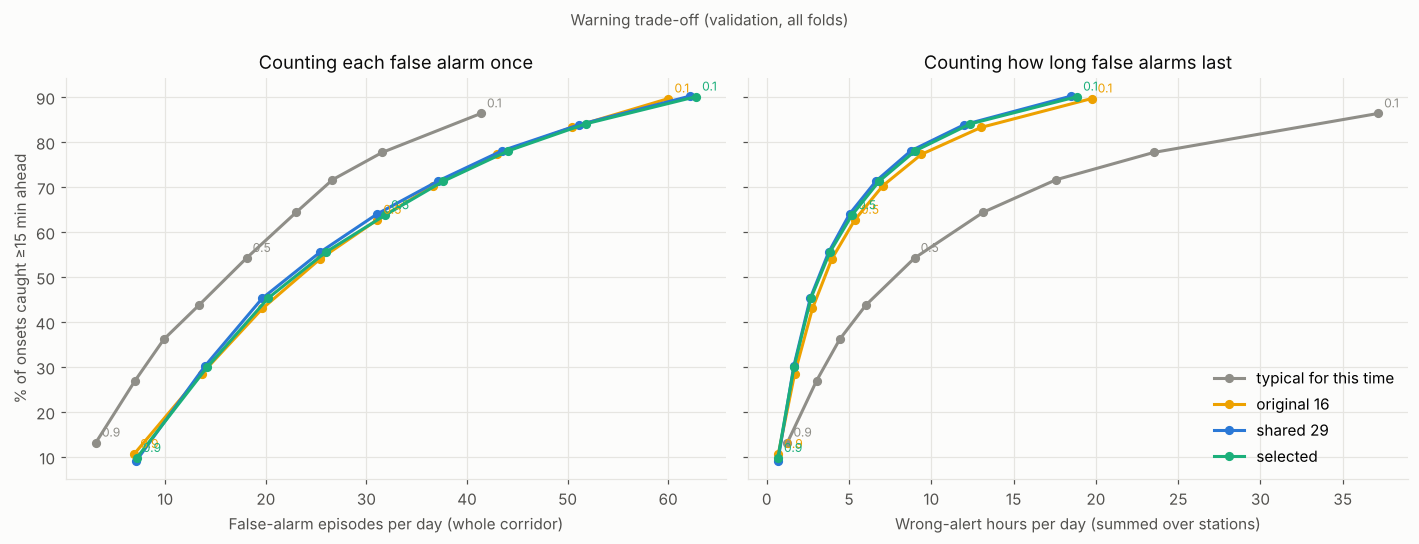

,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min)
0.1,0.901,62.765,18.853,0.753,30.0
0.2,0.841,51.800,12.378,0.820,30.0
0.3,0.781,44.099,9.024,0.859,30.0
0.4,0.713,37.611,6.819,0.888,25.0
0.5,0.637,31.837,5.174,0.911,25.0
0.6,0.555,25.936,3.836,0.930,20.0
0.7,0.453,20.240,2.691,0.948,20.0
0.8,0.299,14.163,1.655,0.966,15.0
0.9,0.098,7.149,0.676,0.984,10.0


In [22]:
all_val = pd.concat(val_predictions, ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)
PLOTTED = ["typical for this time", "original 16", "shared 29", "selected"]
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
tradeoff = {}
for name in PLOTTED:
    tradeoff[name] = pd.DataFrame([sf.alert_metrics(all_val, all_val[name].to_numpy(), t) for t in thresholds], index=thresholds)
    caught_percent = tradeoff[name]["caught ≥15 min"] * 100
    for ax, x_metric in zip(axes, ["false alarms / day", "wrong-alert hours / day"]):
        x = tradeoff[name][x_metric]
        ax.plot(x, caught_percent, color=COLORS[name], marker="o", markersize=5, label=name)
        if name == "shared 29":
            continue                                   # its curve sits on top of "selected", so label the thresholds once
        for threshold in (0.1, 0.5, 0.9):
            ax.annotate(f"{threshold}", (x[threshold], caught_percent[threshold]), xytext=(4, 4),
                        textcoords="offset points", color=COLORS[name], fontsize=8)
axes[0].set_xlabel("False-alarm episodes per day (whole corridor)")
axes[1].set_xlabel("Wrong-alert hours per day (summed over stations)")
axes[0].set_ylabel(f"% of onsets caught ≥{sf.MIN_LEAD_MIN} min ahead")
axes[0].set_title("Counting each false alarm once")
axes[1].set_title("Counting how long false alarms last")
axes[1].legend(loc="lower right")
plt.suptitle("Warning trade-off (validation, all folds)", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()
tradeoff["selected"][["caught ≥15 min", "false alarms / day", "wrong-alert hours / day", "alerts right", "median lead (min)"]].round(3)

## 11. Are the probabilities honest? (calibration)
Predictions grouped into bins of predicted probability and compared with how often congestion actually followed. A well-calibrated model sits on
the diagonal: when it says 70%, congestion happens about 70% of the time.

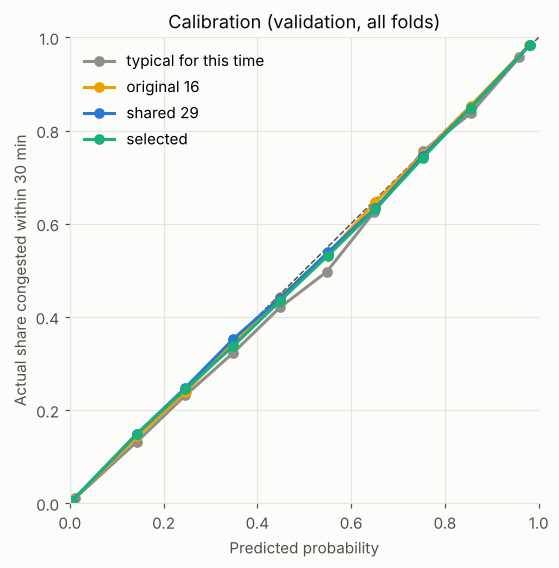

In [23]:
scored = all_val[all_val["y_known"]]
bins = np.linspace(0, 1, 11)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color=INK2, linestyle="--", linewidth=1)
for name in PLOTTED:
    by_bin = scored.groupby(pd.cut(scored[name], bins, include_lowest=True), observed=True)
    calibration = by_bin.agg(predicted=(name, "mean"), actual=("y", "mean"), n=("y", "size"))
    calibration = calibration[calibration["n"] >= 100]
    ax.plot(calibration["predicted"], calibration["actual"], color=COLORS[name], marker="o", markersize=6, label=name)
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Actual share congested within 30 min")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Calibration (validation, all folds)")
ax.legend(loc="upper left")
plt.show()

## 12. What the model relies on
**Permutation importance** for the **selected** model on the last validation fold: shuffle one feature at a time and measure how much average
precision drops, on a sample of that fold's scored rows. Correlated features share credit, so each one in a correlated group looks less important
than the group is (section 7 measures that directly).

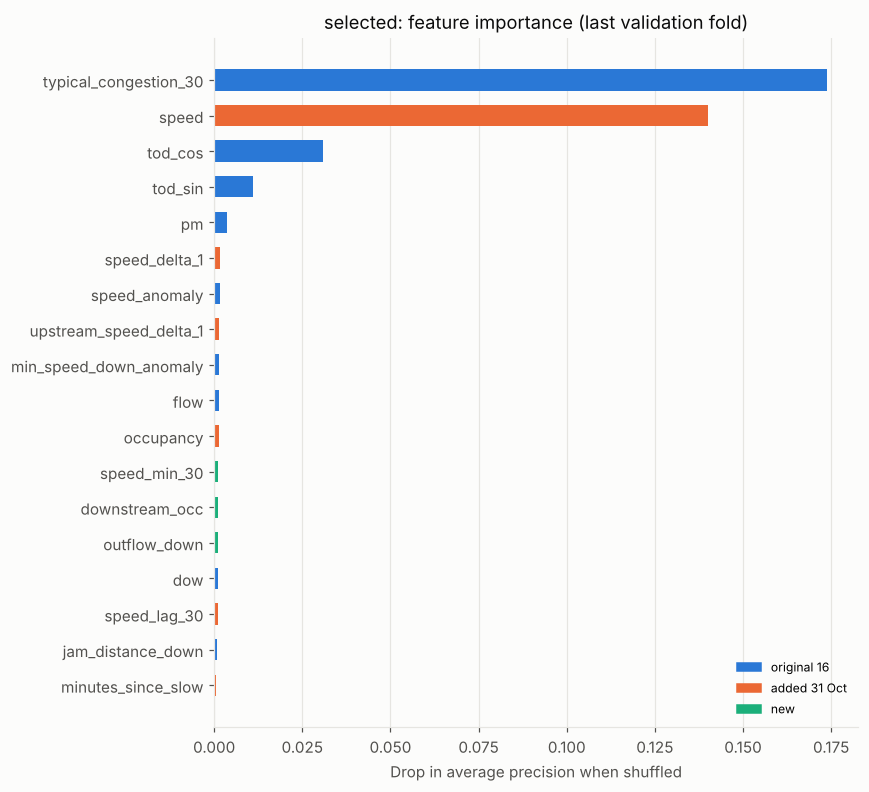

In [24]:
features = FEATURE_SETS["selected"]
sample = last_val[last_val["y_known"]]
sample = sample.sample(min(len(sample), 50_000), random_state=0)
importance = permutation_importance(last_models["selected"], sample[features], sample["y"],
                                    scoring="average_precision", n_repeats=5, random_state=0)
importance = pd.Series(importance.importances_mean, index=features).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.35 * len(features) + 1))
ax.barh(importance.index, importance.values, color=[ORIGIN_COLORS[ORIGIN[f]] for f in importance.index], height=0.6)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_xlabel("Drop in average precision when shuffled")
ax.set_title("selected: feature importance (last validation fold)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ORIGIN_COLORS.values()], list(ORIGIN_COLORS), loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**SHAP values** split each prediction into one contribution per feature: how much that feature pushed the predicted risk up (positive) or down
(negative) compared with an average row, in log-odds (the model's internal scale; +1 roughly multiplies the odds by 2.7). A LightGBM model on the
selected features, the same size as the team's trees, is trained on the last fold's training rows and explained on `SHAP_ROWS` of that quarter's
onset rows.

- **Left, mean |SHAP|:** how much a feature moves predictions on average.
- **Right, beeswarm:** one dot per row. Left/right = lowers/raises the risk; color = the feature's value (blue low, red high).
- **Below, dependence:** for the 4 most important features, how the contribution changes with the feature's value. Flat = that range doesn't
  matter, steep = small changes matter, a step = a threshold, vertical spread = the effect depends on other features.

LightGBM used for SHAP, last fold: AP onsets 0.770 (boosted trees: 0.767)


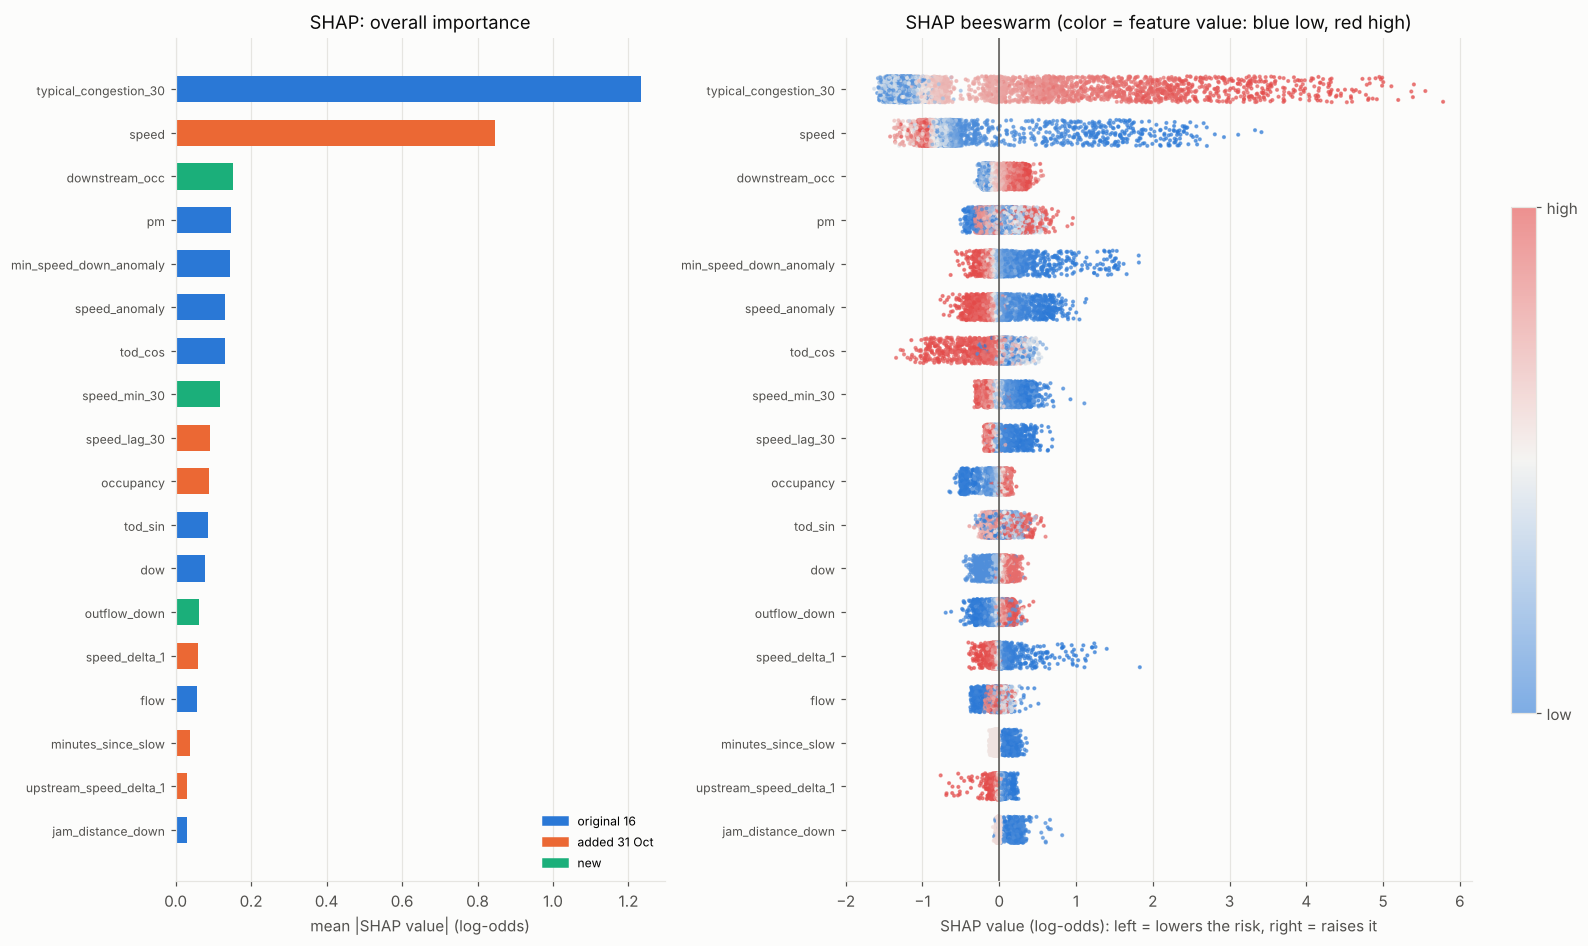

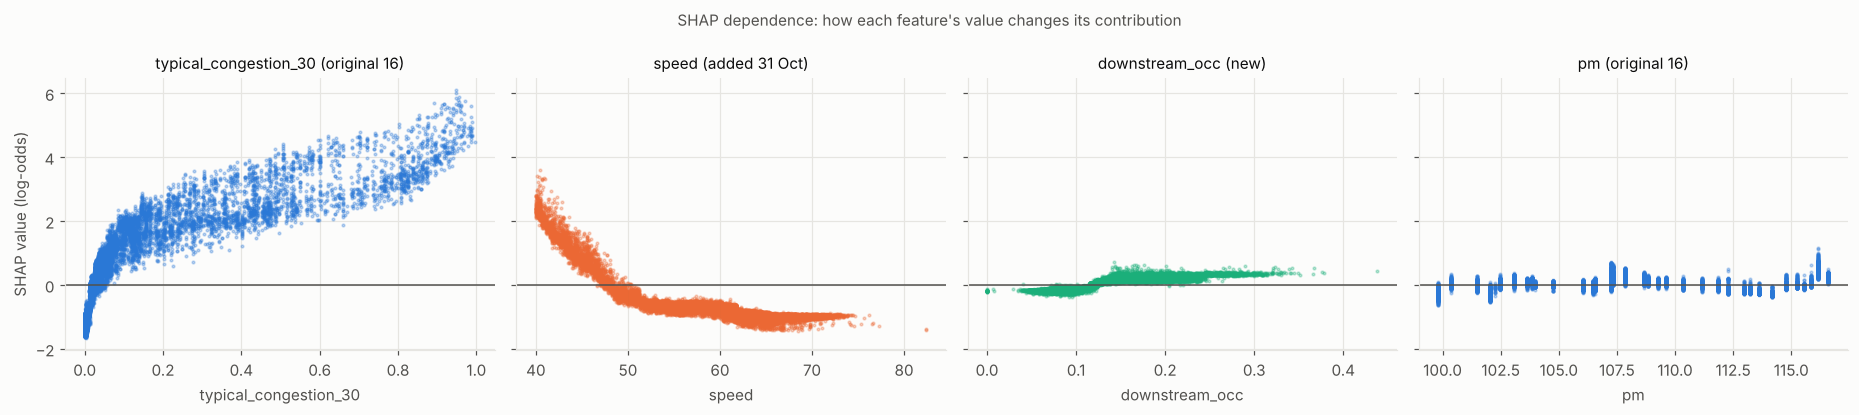

In [25]:
if LGBMClassifier is not None:
    shap_model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, reg_lambda=1.0,
                                verbose=-1, random_state=0)
    shap_model.fit(last_train[features], last_train["y"])
    onset_rows = last_val[last_val["y_known"] & ~last_val["congested_now"] & last_val["real"]]
    shap_ap = average_precision_score(onset_rows["y"], shap_model.predict_proba(onset_rows[features])[:, 1])
    print(f"LightGBM used for SHAP, last fold: AP onsets {shap_ap:.3f} (boosted trees: {per_fold['selected'].iloc[-1]:.3f})")
    shap_rows = onset_rows.sample(min(SHAP_ROWS, len(onset_rows)), random_state=0).reset_index(drop=True)
    shap_values = pd.DataFrame(shap_model.predict(shap_rows[features], pred_contrib=True)[:, :-1], columns=features)
    mean_abs = shap_values.abs().mean().sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(15, 0.4 * len(features) + 1.5), gridspec_kw={"width_ratios": [1, 1.6]})
    axes[0].barh(range(len(mean_abs)), mean_abs.values, height=0.6, color=[ORIGIN_COLORS[ORIGIN[f]] for f in mean_abs.index])
    axes[0].set_yticks(range(len(mean_abs)), mean_abs.index, fontsize=8)
    axes[0].set_xlabel("mean |SHAP value| (log-odds)")
    axes[0].set_title("SHAP: overall importance")
    axes[0].grid(axis="y", visible=False)
    axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ORIGIN_COLORS.values()], list(ORIGIN_COLORS),
                   loc="lower right", fontsize=8)

    rng = np.random.default_rng(0)
    dots = shap_rows.index[:5_000]
    blue_red = LinearSegmentedColormap.from_list("blue_red", [BLUE, "#f0efec", "#e34948"])
    for k, f in enumerate(mean_abs.index):
        axes[1].scatter(shap_values.loc[dots, f], k + rng.uniform(-0.3, 0.3, len(dots)), c=shap_rows.loc[dots, f].rank(pct=True),
                        cmap=blue_red, s=3, alpha=0.6, vmin=0, vmax=1)
    axes[1].axvline(0, color=INK2, linewidth=1)
    axes[1].set_yticks(range(len(mean_abs)), mean_abs.index, fontsize=8)
    axes[1].set_xlabel("SHAP value (log-odds): left = lowers the risk, right = raises it")
    axes[1].set_title("SHAP beeswarm (color = feature value: blue low, red high)")
    axes[1].grid(axis="y", visible=False)
    colorbar = fig.colorbar(axes[1].collections[0], ax=axes[1], ticks=[0, 1], shrink=0.6)
    colorbar.ax.set_yticklabels(["low", "high"])
    plt.tight_layout()
    plt.show()

    top4 = list(mean_abs.index[::-1][:4])
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
    for ax, f in zip(axes, top4):
        ax.scatter(shap_rows[f], shap_values[f], s=3, alpha=0.3, color=ORIGIN_COLORS[ORIGIN[f]])
        ax.axhline(0, color=INK2, linewidth=1)
        ax.set_xlabel(f)
        ax.set_title(f"{f} ({ORIGIN[f]})", fontsize=10)
    axes[0].set_ylabel("SHAP value (log-odds)")
    plt.suptitle("SHAP dependence: how each feature's value changes its contribution", color=INK2, fontsize=10)
    plt.tight_layout()
    plt.show()
else:
    print("SHAP plots skipped: lightgbm is not installed")

## 13. Notes

- **The holdout (July–December 2025) was never read.** Evaluate the final model on it once, at the end.
- **The 13 features added on 31 Oct help the boosted trees.** The shared 29 beat the original 16 in all 6 quarters: +0.018 AP on onsets on
  average, +0.016 on the last three. With boosted trees, the 29 reach 0.767, above the transformer (0.763) and the random forest (0.750) in
  `results/summary.csv`. A boosted-trees run on the 29 isn't in the summary yet and is worth adding.
- **The 4 new features don't add anything on top of the 29.** All four beat random noise (check b), but adding them lowers AP on the last three
  quarters (−0.010, worse in 3 of 3, most of it in 2024 Q4). They mostly repeat what the 29 already carry: `speed_min_30` correlates 0.95 with
  `speed`, and `typical_in_30` −0.89 with `typical_congestion_30`. Not worth adding to `safeflow_features.py`.
- **A leaner set of 18 features loses little.** The selected set scores 0.763 on the last three quarters against 0.766 for the 29 (−0.003, better
  in 1 of 3). The 15 features that never earn their place: `occ_anomaly`, `speed_delta_2`, `speed_delta_3`, `down_minus_here`, `up_minus_here`,
  `onramp_flow_up`, `offramp_flow_down`, `jam_distance_change_10`, `upstream_speed_delta_2/3`, `downstream_speed_delta_1/2`,
  `upstream_distance_miles`, `slow_last_30` and `typical_in_30`. Useful if a model needs fewer inputs; otherwise keep the 29.
- **Two features carry most of the model:** `typical_congestion_30` (does this station usually jam at this time?) and `speed` (how slow is it now?).
  Both permutation importance and SHAP agree; everything else is a small correction. Speed matters only between about 40 and 55 mph (SHAP
  dependence), and downstream occupancy acts like an on/off threshold at roughly 0.12–0.15.
- **The sets differ little on the map.** Their trade-off curves and calibration nearly coincide, so the choice between them is about simplicity,
  not alert quality. As in `feature_selection.ipynb`, *typical for this time* looks good on false-alarm episodes but wastes far more alert time.
- **No look-ahead** in the two new features or the 10 recomputable features added on 31 Oct (section 2).
- **34% of the rows counted as "recently slow" have no measured slow reading.** `slow_last_30` and `minutes_since_slow` also count readings PeMS
  filled in. Counting only measured readings (`real`) would match how the target is defined; agree that with the team before changing the shared file.
- **Choosing on the first three quarters biases their scores upward slightly.** That's why only the last three quarters are used to judge the
  selected set, and why the holdout is kept for one final check.
- **Check (c) uses a faster model** (150 trees, 300,000 rows), so its small differences are noisy. The six-quarter comparison in section 9, with the
  team's exact model, is the deciding test.